# Lab 11 - Looking inside a CNN: filters, initialization and noise

Lucas Schwengber/Josh Davis

LLM assistance was used during the elaboration of this lab.

# Learning goals

The learning goals of this lab are:

1.  Understand a little bit of the structure behind the representations
    of a trained CNN.
2.  Understand the relevance of initializing weights with the right
    scale in deep networks.
3.  Understand the relevance of making the trained network robust to
    possible perturbations of the data.

# Setup

We reuse the data, `train`, `evaluate`, `shift` and `shift_accuracy`
from lab 10, and keep the first 2,000 test images as tensors `x_test`
and `y_test` for the figures. To run this notebook,
<a href="../lab10_neural_nets/lab10_code.py"
download="lab10_code.py">download <code>lab10_code.py</code></a> from
lab 10 and put it in the same folder as your notebook (on Google Colab,
upload it with the folder icon on the left).

In [1]:
import sys
sys.path.append("../lab10_neural_nets")      # not needed if lab10_code.py is in the same folder as this notebook
from lab10_code import *                     # the first import downloads MNIST to ./data

x_test = torch.stack([test_set[i][0] for i in range(2000)])       # 2,000 test images, shape (2000, 1, 28, 28)
y_test = torch.tensor([test_set[i][1] for i in range(2000)])

print(f"PyTorch {torch.__version__}, device: {device}")

PyTorch 2.11.0+cu130, device: cpu

# Edge detectors and channels

In lab 10 we designed two edge detectors by hand and said that a CNN
learns its kernels from the data. Here we look at what it learns.

## A CNN with larger first-layer kernels

Consider a CNN like `make_cnn()` from the previous lab, with two
changes: the first convolution has $5 \times 5$ kernels instead of
$3 \times 3$, and every convolution has half as many channels (8, 16 and
32 instead of 16, 32 and 64). The diagram shows the shape of the data
after each layer, for one image: $C \times H \times W$ is $C$ channels
(feature maps) of $H \times W$ values. Each value of a channel of the
first convolution is computed from the $5 \times 5$ pixels around it,
like the red square; the same kernel slides over every position. The
argument `first_scale` of `make_cnn5` multiplies the initial weights of
the first convolution (and sets its biases to zero); we use it below.

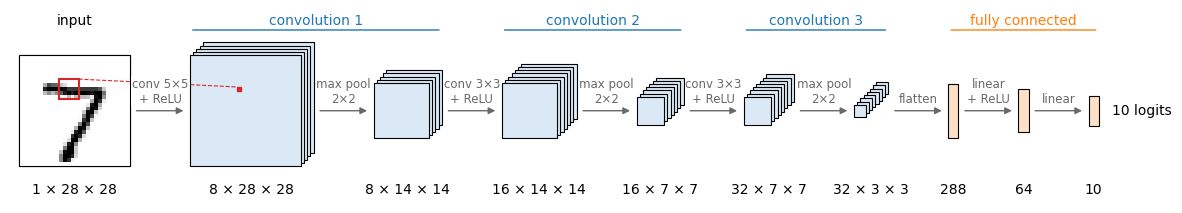

In [2]:
from matplotlib.patches import Rectangle, FancyArrowPatch

# the tensors that one image goes through: (channels, height and width) for feature maps, (length,) for vectors
stages = [(1, 28), (8, 28), (8, 14), (16, 14), (16, 7), (32, 7), (32, 3), (288,), (64,), (10,)]
ops = ["conv 5×5\n+ ReLU", "max pool\n2×2", "conv 3×3\n+ ReLU", "max pool\n2×2", "conv 3×3\n+ ReLU",
       "max pool\n2×2", "flatten", "linear\n+ ReLU", "linear"]
SCALE, STEP, GAP = 2.4 / 28, 0.07, 1.3      # size of a pixel, offset between drawn channels, space for an arrow
fig, ax = plt.subplots(figsize=(15, 3.4))
x, boxes = 0.0, []
for s in stages:
    if len(s) == 2:                              # a stack of C feature maps, drawn as a few offset sheets
        C, H = s
        n_sheets = int(1 + 1.5 * np.log2(C))
        side = H * SCALE
        for k in range(n_sheets):
            ax.add_patch(Rectangle((x + k * STEP, -side / 2 + k * STEP), side, side,
                                   facecolor="#dbe9f6", edgecolor="black", lw=0.8, zorder=10 - k))
        width = side + (n_sheets - 1) * STEP
        label = f"{C} × {H} × {H}"
    else:                                        # a vector, drawn as a bar
        side, width = 0.35 * np.log10(s[0]) + 0.3, 0.22
        ax.add_patch(Rectangle((x, -side / 2), width, side, facecolor="#fde0c5", edgecolor="black", lw=0.8))
        label = f"{s[0]}"
    boxes.append((x, width))
    ax.text(x + width / 2, -1.55, label, ha="center", va="top", fontsize=10)
    x += width + GAP

# the input image inside the first box, with a 5 x 5 window and the value of channel 0 that it gives
x0 = boxes[0][0]
ax.imshow(test_set[0][0][0], cmap="gray_r", extent=(x0, x0 + 28 * SCALE, -14 * SCALE, 14 * SCALE), zorder=11)
ax.add_patch(Rectangle((x0, -14 * SCALE), 28 * SCALE, 28 * SCALE, fill=False, edgecolor="black", lw=0.8, zorder=12))
r, c = 8, 12                                     # center of the window (row, column)
ax.add_patch(Rectangle((x0 + (c - 2) * SCALE, (14 - r - 3) * SCALE), 5 * SCALE, 5 * SCALE,
                       fill=False, edgecolor="C3", lw=1.5, zorder=12))
x1 = boxes[1][0]
ax.add_patch(Rectangle((x1 + c * SCALE, (14 - r - 1) * SCALE), SCALE, SCALE, color="C3", zorder=12))
ax.plot([x0 + (c + 3) * SCALE, x1 + c * SCALE], [(14 - r + 2) * SCALE, (14 - r) * SCALE],
        color="C3", lw=0.8, ls="--", zorder=12)

for (xa, wa), (xb, _), op in zip(boxes[:-1], boxes[1:], ops):
    ax.add_patch(FancyArrowPatch((xa + wa + 0.08, 0), (xb - 0.08, 0), arrowstyle="-|>", mutation_scale=10,
                                 color="dimgray", zorder=20))
    ax.text((xa + wa + xb) / 2, 0.12, op, ha="center", va="bottom", fontsize=8.5, color="dimgray", zorder=20,
            bbox=dict(facecolor="white", edgecolor="none", pad=0.5))

# the three convolution blocks and the fully connected part
for k, (first, last) in enumerate([(1, 2), (3, 4), (5, 6)]):
    xa, xb = boxes[first][0], boxes[last][0] + boxes[last][1]
    ax.annotate("", (xa, 1.75), (xb, 1.75), arrowprops=dict(arrowstyle="-", color="C0"))
    ax.text((xa + xb) / 2, 1.82, f"convolution {k + 1}", ha="center", va="bottom", fontsize=10, color="C0")
xa, xb = boxes[7][0], boxes[9][0] + boxes[9][1]
ax.annotate("", (xa, 1.75), (xb, 1.75), arrowprops=dict(arrowstyle="-", color="C1"))
ax.text((xa + xb) / 2, 1.82, "fully connected", ha="center", va="bottom", fontsize=10, color="C1")
ax.text(boxes[0][0] + boxes[0][1] / 2, 1.82, "input", ha="center", va="bottom", fontsize=10)
ax.text(boxes[-1][0] + 0.5, 0, "10 logits", ha="left", va="center", fontsize=10)

ax.set_xlim(-0.2, x + 0.3)
ax.set_ylim(-2.0, 2.2)
ax.set_aspect("equal")
ax.axis("off")
plt.show()

In [3]:
def make_cnn5(first_scale=1.0):
    model = nn.Sequential(
        nn.Conv2d(1, 8, kernel_size=5, padding=2), nn.ReLU(), nn.MaxPool2d(2),      # 1 x 28 x 28 -> 8 x 14 x 14
        nn.Conv2d(8, 16, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),     # -> 16 x 7 x 7
        nn.Conv2d(16, 32, kernel_size=3, padding=1), nn.ReLU(), nn.MaxPool2d(2),    # -> 32 x 3 x 3
        nn.Flatten(),                                                               # -> 32 * 3 * 3 = 288
        nn.Linear(32 * 3 * 3, 64), nn.ReLU(),
        nn.Linear(64, 10),
    )
    if first_scale != 1.0:
        with torch.no_grad():
            model[0].weight *= first_scale
            model[0].bias.zero_()
    return model


torch.manual_seed(0)
cnn_default = make_cnn5()
train(cnn_default, train_loader, n_epochs=3)
print(f"test accuracy {evaluate(cnn_default, test_loader)[1]:.1%}")

  epoch  1: training loss 0.465, validation loss 0.158, validation accuracy 95.3%
  epoch  2: training loss 0.111, validation loss 0.093, validation accuracy 97.2%
  epoch  3: training loss 0.081, validation loss 0.082, validation accuracy 97.4%
test accuracy 98.0%

## Training

We now train the CNN with two modifications relative to the training of
`cnn_default`:

- the initial weights of the first convolution are multiplied by 0.05,
  so that what training adds dominates;
- the training images get random pixel noise (for each minibatch, a
  standard deviation drawn uniformly between 0 and 0.5). Section 3 comes
  back to this *noise augmentation*.

The goal is to make sure the trained kernels are robust, and are indeed
learned, as opposed to being merely inherited from a large random
initialization.

`train` adds the noise to the validation images too, so the validation
accuracies printed below are on noisy images, while the test accuracy is
on clean ones.

In [4]:
def kernel_similarity(W_a, W_b):
    """Absolute cosine similarity between matching kernels of two weights of shape (channels, 1, k, k)."""
    return F.cosine_similarity(W_a.flatten(1), W_b.flatten(1)).abs().numpy()


def roughness(W):
    """Mean squared difference between neighboring kernel pixels over twice the mean square of the kernel:
    about 1 for independent noise, close to 0 for a smooth kernel."""
    W = W[:, 0]
    d = torch.cat([(W[:, 1:] - W[:, :-1]).flatten(1), (W[:, :, 1:] - W[:, :, :-1]).flatten(1)], dim=1)
    return ((d ** 2).mean(dim=1) / (2 * (W ** 2).mean(dim=(1, 2)))).numpy()


def add_noise(images, sd):
    """Add independent normal noise with standard deviation sd to every pixel."""
    return images + sd * torch.randn_like(images)


def random_noise(images):
    return add_noise(images, 0.5 * torch.rand(1).item())


torch.manual_seed(0)
cnn = make_cnn5(first_scale=0.05)
W1_init = cnn[0].weight.detach().clone()
train(cnn, train_loader, n_epochs=3, transform=random_noise)
print(f"test accuracy {evaluate(cnn, test_loader)[1]:.1%}")

cnn.cpu()
sim = kernel_similarity(cnn[0].weight.detach(), W1_init)
print("similarity to the initial kernel, per channel: " + " ".join(f"{v:.2f}" for v in sim) + f"   median {np.median(sim):.2f}")
print(f"roughness, median over channels: {np.median(roughness(cnn[0].weight.detach())):.2f}")
print("sum of each kernel / sum of its absolute values: "
      + " ".join(f"{v:+.2f}" for v in (cnn[0].weight.detach().sum(dim=(1, 2, 3)) / cnn[0].weight.detach().abs().sum(dim=(1, 2, 3))).numpy()))
print("biases: " + " ".join(f"{v:+.2f}" for v in cnn[0].bias.detach().numpy()))

  epoch  1: training loss 0.750, validation loss 0.264, validation accuracy 91.7%
  epoch  2: training loss 0.176, validation loss 0.185, validation accuracy 93.9%
  epoch  3: training loss 0.134, validation loss 0.114, validation accuracy 96.5%
test accuracy 97.8%
similarity to the initial kernel, per channel: 0.14 0.09 0.22 0.25 0.05 0.30 0.45 0.02   median 0.18
roughness, median over channels: 0.19
sum of each kernel / sum of its absolute values: +0.18 +1.00 +0.53 +0.23 +0.72 -0.14 +0.50 +0.98
biases: +0.06 -0.10 -0.07 +0.05 -0.16 +0.11 +0.03 -0.09

The first row shows the 8 kernels of this network. The other rows show
what each channel computes, after the ReLU, on a 7 and on a 0.

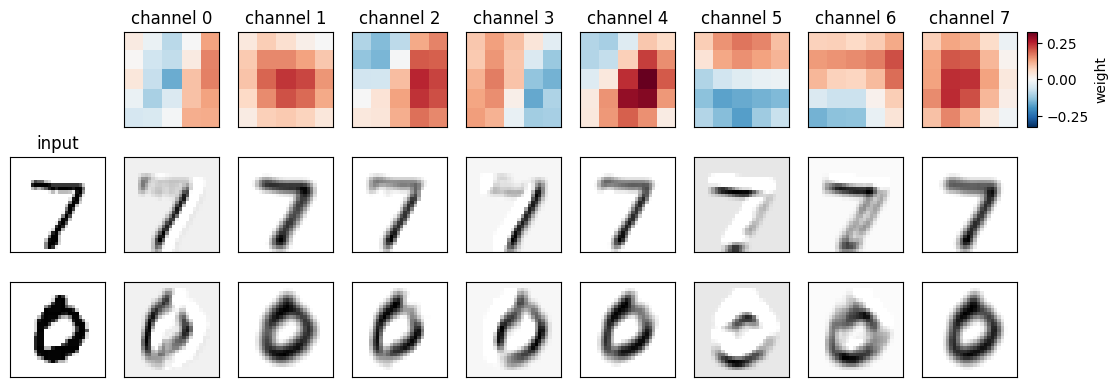

In [5]:
cnn.cpu()
W1 = cnn[0].weight.detach()                      # shape (8, 1, 5, 5): (out channels, in channels, height, width)
examples = [x_test[0], x_test[(y_test == 0).nonzero()[0, 0]]]     # a 7 and a 0

fig, axes = plt.subplots(3, 9, figsize=(13, 4.6))
axes[0, 0].axis("off")
v = W1.abs().max()                               # the same color scale for all kernels
for k in range(8):
    im = axes[0, k + 1].imshow(W1[k, 0], cmap="RdBu_r", vmin=-v, vmax=v)
    axes[0, k + 1].set_title(f"channel {k}")
cax = axes[0, 8].inset_axes([1.1, 0, 0.1, 1])    # colorbar to the right of the last kernel
fig.colorbar(im, cax=cax, label="weight")
for r, img in enumerate(examples, start=1):
    with torch.no_grad():
        maps = F.relu(cnn[0](img[None]))[0]      # shape (8, 28, 28)
    axes[r, 0].imshow(img[0], cmap="gray_r")
    for k in range(8):
        axes[r, k + 1].imshow(maps[k], cmap="gray_r", vmin=0, vmax=max(maps[k].max().item(), 1e-6))
axes[1, 0].set_title("input")
for ax in axes.ravel():
    ax.set(xticks=[], yticks=[])
plt.show()

The test accuracy is about the same as that of `cnn_default` (97.8%
against 98.0%), and the kernels have little to do with their initial
values (median similarity 0.18, close to the 0.16 expected between two
unrelated random kernels of 25 weights) and are smooth (roughness 0.19).
Three kinds of channels can be read off the kernels, with the help of
the two printed lines: a kernel whose sum is close to 0 compared with
the sum of its absolute values takes *differences*, and one where the
ratio is close to 1 takes an *average*.

- **Edge detectors** (5, 3 and 0; ratios $-0.14$, $0.23$ and $0.18$).
  Channel 5 is the cleanest: positive in the top rows and negative in
  the bottom rows. This is the horizontal edge detector of lab 10 with
  the sign flipped: that one was negative on top and positive below, so
  it was positive where the ink is below an edge, and channel 5 is
  positive where the ink is above one. On the 7 it keeps the horizontal
  bar and nothing of the long stroke; on the 0, the top and the bottom
  of the ring. Channels 0 and 3 have their positive and negative parts
  side by side, and keep the strokes that are close to vertical.
- **Ink detectors** (1 and 7; ratios 1.00 and 0.98). Their kernels are
  positive everywhere: they blur the image, like the blur of lab 10.
- **In between** (2, 4 and 6; ratios 0.53, 0.72 and 0.50). Mostly
  positive, but with the weight on one side or along one direction.

The background of channels 0, 3 and 5 is gray instead of white because
their biases are positive (+0.06, +0.05 and +0.11): these channels are
slightly on where there is no ink. The bias of channel 6 is positive
too, but too small (+0.03) to show.

Here an *edge detector* is meant in the image-processing sense: a kernel
that matches a patch that is dark on one side of a line and light on the
other (a *step edge*), like the edge detectors of lab 10. Its positive
half wants ink and its negative half wants none, so it also tells *on
which side* of the edge the ink is.

## Tuning curves

To measure what a channel prefers, we show the network a synthetic image
that is exactly the pattern of an edge detector: a *half-plane*, with
ink on one side of a straight line through the center and none on the
other. We call $\theta$ the direction in which the ink side lies,
counterclockwise from the right: at $0°$ the right half of the image has
ink, at $90°$ the top half. We record the value of each channel at the
center of the image, on the boundary. Doing this for $\theta$ from $0°$
to $360°$ gives the *tuning curve* of the channel. Going around the full
circle matters: the half-planes at $\theta$ and $\theta + 180°$ have
their boundary in the same direction but the ink on opposite sides.

In [6]:
def half_plane(theta_deg, width=0.5):
    """A 28 x 28 image with ink on one side of a straight line through the center. theta is the direction,
    counterclockwise from the right, in which the ink side lies (0: right half, 90: top half). The boundary is
    a logistic step: the ink goes from 10% to 90% over about 4.4 * width pixels."""
    theta = np.deg2rad(theta_deg)
    r, c = np.mgrid[0:28, 0:28] - 13.5
    x, y = c, -r                                           # y points up
    s = x * np.cos(theta) + y * np.sin(theta)              # signed distance to the line, positive on the ink side
    return torch.tensor(1 / (1 + np.exp(-s / width)), dtype=torch.float32)[None]


angles = np.arange(0, 360, 5)
halves = torch.stack([half_plane(a) for a in angles])      # shape (72, 1, 28, 28)
with torch.no_grad():
    maps = F.relu(cnn[0](halves))                          # shape (72, 8, 28, 28)
tuning = maps[:, :, 13:15, 13:15].mean(dim=(2, 3)).numpy() # value at the center, on the boundary: shape (72, 8)


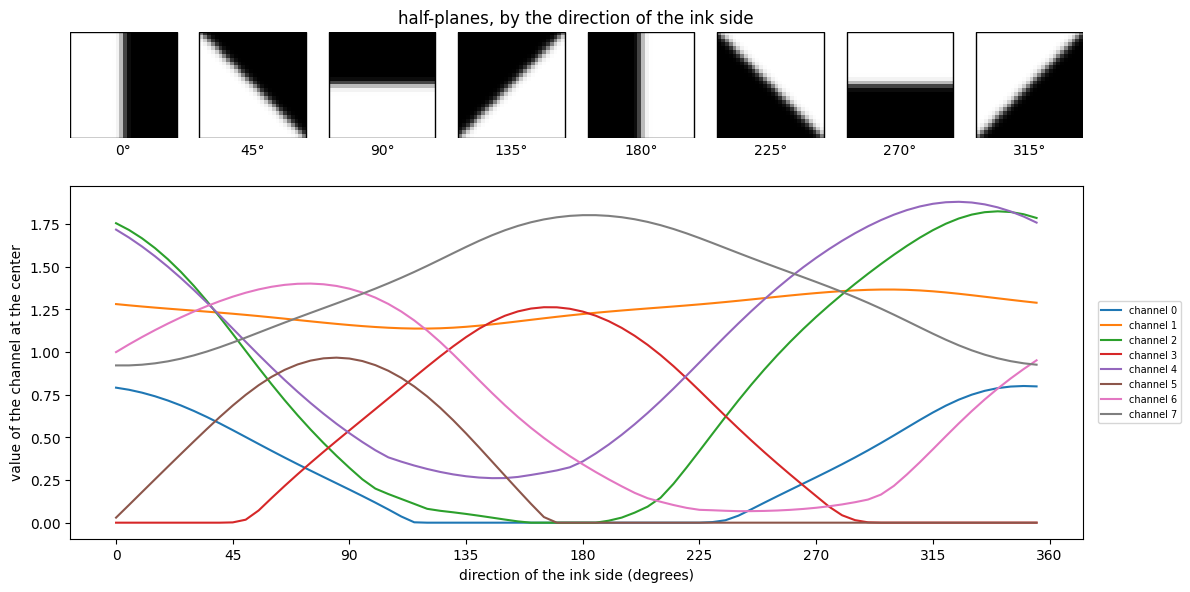

channel 0: prefers 350°,  largest value 0.80,  smallest 0.00 (at 120°)
channel 1: prefers 300°,  largest value 1.37,  smallest 1.14 (at 120°)
channel 2: prefers 340°,  largest value 1.83,  smallest 0.00 (at 160°)
channel 3: prefers 165°,  largest value 1.26,  smallest 0.00 (at   0°)
channel 4: prefers 325°,  largest value 1.88,  smallest 0.26 (at 145°)
channel 5: prefers  85°,  largest value 0.97,  smallest 0.00 (at 170°)
channel 6: prefers  75°,  largest value 1.40,  smallest 0.07 (at 240°)
channel 7: prefers 180°,  largest value 1.80,  smallest 0.92 (at   0°)

In [7]:
shown = range(0, 360, 45)
gap = 6                                                    # white space between the examples, in pixels
fig, axes = plt.subplots(2, 1, figsize=(12, 6.2), gridspec_kw={"height_ratios": [1, 1.9]})
axes[0].imshow(torch.cat([F.pad(half_plane(a)[0], (0, gap)) for a in shown], dim=1)[:, :-gap], cmap="gray_r")
for j in range(len(shown)):                                # a black frame around each example
    axes[0].add_patch(plt.Rectangle((j * (28 + gap) - 0.5, -0.5), 28, 28, fill=False, edgecolor="black", lw=1))
axes[0].set(xticks=[13.5 + j * (28 + gap) for j in range(len(shown))], xticklabels=[f"{a}°" for a in shown],
            yticks=[], title="half-planes, by the direction of the ink side")
axes[0].tick_params(length=0)
for side in axes[0].spines.values():
    side.set_visible(False)
for k in range(8):
    axes[1].plot(angles, tuning[:, k], label=f"channel {k}")
axes[1].set(xlabel="direction of the ink side (degrees)", ylabel="value of the channel at the center",
            xticks=range(0, 361, 45))
axes[1].legend(fontsize=7, loc="center left", bbox_to_anchor=(1.01, 0.5))
fig.tight_layout()
plt.show()

for k in range(8):
    t = tuning[:, k]
    print(f"channel {k}: prefers {angles[t.argmax()]:3d}°,  largest value {t.max():.2f},  smallest {t.min():.2f} (at {angles[t.argmin()]:3d}°)")


The tuning curves agree with the kernels, and they read the kernels as
half-planes. A channel is zero (the ReLU clips it) when the ink is on
the side its negative weights cover.

## Channels: what the deeper layers see

The first convolution takes 1 channel (the image) to 8. The second takes
those 8 channels to 16, and its weight has four dimensions:

In [8]:
for i in (0, 3, 6):
    conv = cnn[i]
    c_out, c_in, k, _ = conv.weight.shape
    print(f"layer {i}: weight shape {tuple(conv.weight.shape)} = (out channels, in channels, height, width),  "
          f"each output adds up N = {k} x {k} x {c_in} = {k * k * c_in} inputs")

layer 0: weight shape (8, 1, 5, 5) = (out channels, in channels, height, width),  each output adds up N = 5 x 5 x 1 = 25 inputs
layer 3: weight shape (16, 8, 3, 3) = (out channels, in channels, height, width),  each output adds up N = 3 x 3 x 8 = 72 inputs
layer 6: weight shape (32, 16, 3, 3) = (out channels, in channels, height, width),  each output adds up N = 3 x 3 x 16 = 144 inputs

Each output channel of the second convolution has one $3 \times 3$
kernel *per input channel*, and adds the 8 results: it looks for a
combination of first-layer features in a small neighborhood. An output
pixel is therefore a weighted sum of $N = K^2 C_{\text{in}}$ inputs
(this $N$ comes back in
<a href="#sec-init" class="quarto-xref">Section 2</a>).

The idea of these channels is to assemble information from the edge
detectors to detect more complicated structures such as large regions
forming an edge with the same orientation, or compositions of edges
forming more complicated structures.

Consider the two examples next showing channels 0 and 10 from the second
convolutional layer.

- **Channel 0**: detects a larger edge on the right from smaller ones.
- **Channel 10**: detects two separate edges one on the left and one on
  the right (which is something not detectable by any individual kernel
  from the first convolutional layer).

Channel 0 is able to detect the large edge in two different ways: one by
just checking whether the edge detectors with the same target patterns
are strongly activated on one side of the region, and the other by
building an edge detector itself to operate on the channels which just
detect whether ink is present in the region or not.

Channel 10 on the other hand, checks for an edge on the right of the
region, for example by looking at channel 4, and one edge on the left,
for example by looking at channel 3. If both of these are found
(together with similar patterns captured by other edges), the channel is
high on the region, indicating a composition of one edge on the left and
one on the right separated by a white space.

Note that the presence of a shape like this is strongly indicative of
the image being a 0 or 4, and certainly not a 1 or a 7 for example.

This is exactly the type of “features” one would like to have to
classify handwriting in general. What is striking is that the neural
network learns these on its own, without requiring a human to manually
engineer those features.

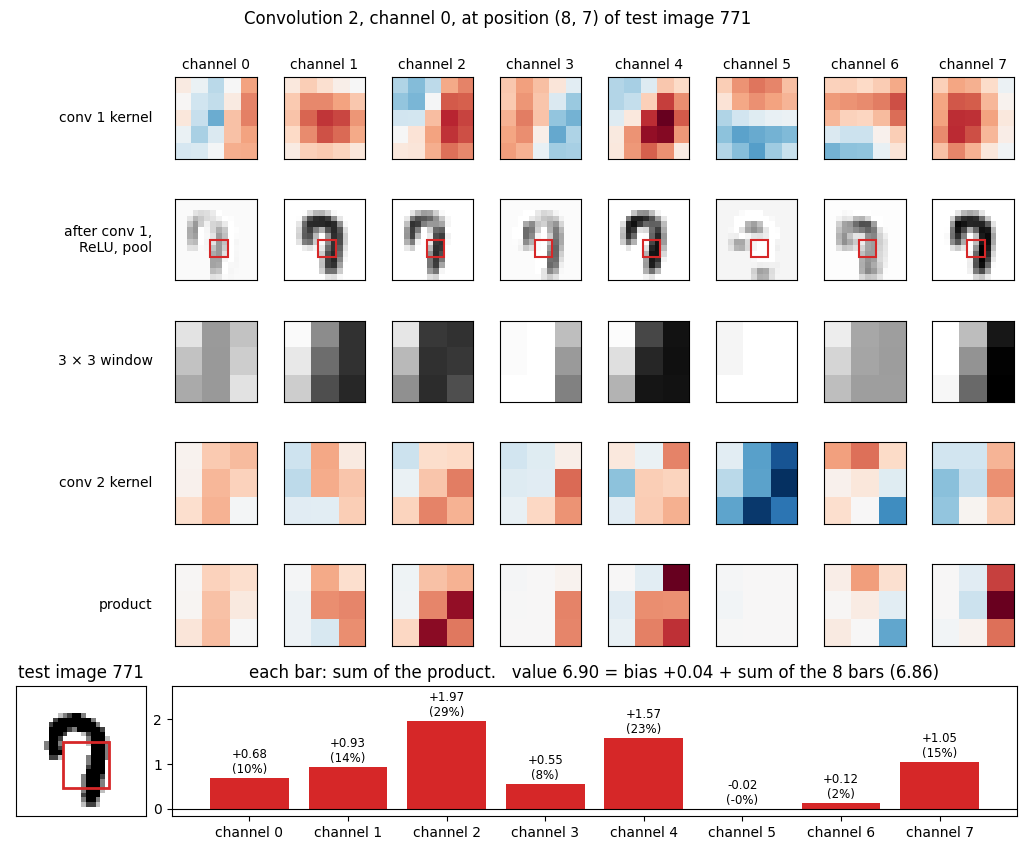

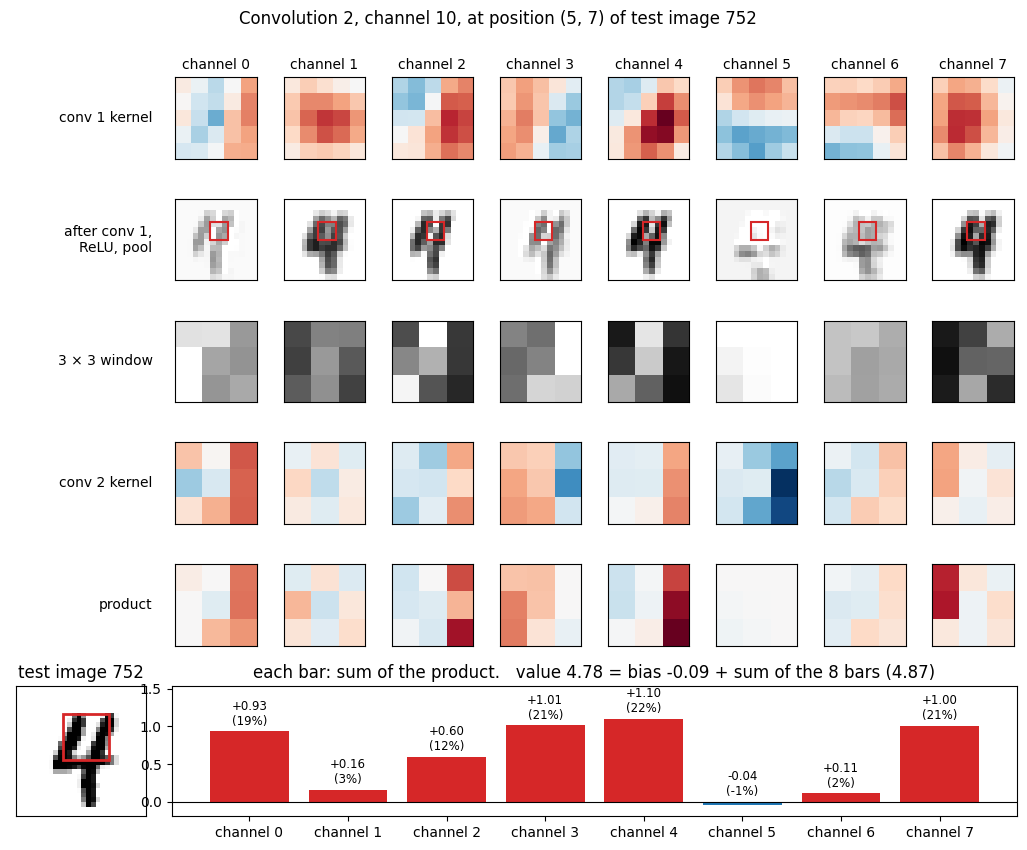

In [9]:
def show_decomposition(ch, img=None):
    """Channel ch of convolution 2 at its largest value in image img (by default the test image that ranks first),
    split into the contributions of the 8 input channels: bias + sum over k of (3 x 3 kernel k) * (3 x 3 window of channel k)."""
    with torch.no_grad():
        P1 = cnn[:3](x_test)                                    # input of convolution 2: (2000, 8, 14, 14)
        A2 = cnn[:5](x_test)[:, ch]                             # channel ch of convolution 2, after the ReLU
    best, where = A2.reshape(len(x_test), -1).max(dim=1)
    if img is None:
        img = best.argmax().item()
    i, j = divmod(where[img].item(), 14)
    W1 = cnn[0].weight.detach()                                 # first-layer kernels: (8, 1, 5, 5)
    W = cnn[3].weight.detach()[ch]                              # the 8 kernels of channel ch, one per input channel: (8, 3, 3)
    b = cnn[3].bias.detach()[ch].item()
    window = F.pad(P1[img], (1, 1, 1, 1))[:, i:i + 3, j:j + 3]  # the 3 x 3 window of each input channel (zero padding)
    terms = W * window
    contrib = terms.sum(dim=(1, 2)).numpy()                     # value = bias + sum of contrib

    fig = plt.figure(figsize=(13, 9.6))
    gs = fig.add_gridspec(6, 9, height_ratios=[1, 1, 1, 1, 1, 1.6], width_ratios=[1.6] + [1] * 8, hspace=0.45)
    ax = fig.add_subplot(gs[5, 0])
    ax.imshow(x_test[img, 0], cmap="gray_r", vmin=0, vmax=1)
    ax.add_patch(plt.Rectangle((2 * j - 4 - 0.5, 2 * i - 4 - 0.5), 10, 10, fill=False, edgecolor="C3", lw=2))
    ax.set(xticks=[], yticks=[], xlim=(-0.5, 27.5), ylim=(27.5, -0.5), title=f"test image {img}")
    labels = ["conv 1 kernel", "after conv 1,\nReLU, pool", "3 × 3 window", "conv 2 kernel", "product"]
    for r, text in enumerate(labels):
        a = fig.add_subplot(gs[r, 0]); a.axis("off")
        a.text(1, 0.5, text, ha="right", va="center", fontsize=10, transform=a.transAxes)
    v1, vmap, vw, vt = W1.abs().max(), P1[img].max(), W.abs().max(), terms.abs().max()
    for k in range(8):
        rows = [(W1[k, 0], "RdBu_r", -v1, v1), (P1[img, k], "gray_r", 0, vmap), (window[k], "gray_r", 0, vmap),
                (W[k], "RdBu_r", -vw, vw), (terms[k], "RdBu_r", -vt, vt)]
        for r, (m, cmap, lo, hi) in enumerate(rows):
            a = fig.add_subplot(gs[r, k + 1])
            a.imshow(m, cmap=cmap, vmin=lo, vmax=hi)
            a.set(xticks=[], yticks=[])
            if r == 0:
                a.set_title(f"channel {k}", fontsize=10)
            if r == 1:
                a.add_patch(plt.Rectangle((j - 1.5, i - 1.5), 3, 3, fill=False, edgecolor="C3", lw=1.5))
    ax = fig.add_subplot(gs[5, 1:])
    ax.bar(range(8), contrib, color=["C3" if c > 0 else "C0" for c in contrib])
    for k, c in enumerate(contrib):
        ax.text(k, max(c, 0) + 0.05, f"{c:+.2f}\n({c / contrib.sum():.0%})", ha="center", va="bottom", fontsize=8.5)
    ax.axhline(0, color="black", lw=0.8)
    ax.set(xticks=range(8), xticklabels=[f"channel {k}" for k in range(8)],
           ylim=(min(0, contrib.min()) - 0.15, contrib.max() * 1.4),
           title=f"each bar: sum of the product.   value {A2[img, i, j]:.2f} = bias {b:+.2f} + sum of the 8 bars ({contrib.sum():.2f})")
    fig.suptitle(f"Convolution 2, channel {ch}, at position ({i}, {j}) of test image {img}", y=0.95, fontsize=12)
    plt.show()


show_decomposition(0)        # a larger edge, built from smaller ones
show_decomposition(10)       # two edges facing each other across a gap

These figures look at one image at a time. A broader way to see what a
channel of a deeper convolution detects is to look for the parts of
images that make it the largest.

**Receptive fields.** Each value of a feature map depends only on a
square patch of the input image, its *receptive field*. After the first
convolution, the value at position $(i, j)$ depends on the $5 \times 5$
pixels around pixel $(i, j)$ (the red square in the diagram at the top).
The receptive field grows with every layer:

| after | feature maps | one step between neighboring values | receptive field (pixels) |
|------------------|------------------|------------------|------------------|
| convolution 1 | $8 \times 28 \times 28$ | 1 pixel | $5 \times 5$ |
| max pooling 1 | $8 \times 14 \times 14$ | 2 pixels | $6 \times 6$ |
| convolution 2 | $16 \times 14 \times 14$ | 2 pixels | $10 \times 10$ |
| max pooling 2 | $16 \times 7 \times 7$ | 4 pixels | $12 \times 12$ |
| convolution 3 | $32 \times 7 \times 7$ | 4 pixels | $20 \times 20$ |

**The patches that activate a channel the most.** For one channel of one
convolution, we:

1.  pass the 2,000 test images through the network up to that
    convolution and its ReLU (before the pooling), which gives one
    feature map of the channel per image;
2.  find, in each image, the position $(i, j)$ where the channel is
    largest;
3.  rank the images by this largest value, and keep the first 8;
4.  cut out of each of these 8 images the receptive field of its
    position $(i, j)$.

`top_patches` does these four steps for every channel at once. The
arguments `step`, `offset` and `size` describe the receptive fields of
the table: the value at position $(i, j)$ depends on the pixels in rows
$\text{step} \cdot i - \text{offset}$ to
$\text{step} \cdot i - \text{offset} + \text{size} - 1$, and likewise
for the columns. For convolution 2, for example, position $(i, j)$ sees
rows $2i - 4$ to $2i + 5$.

In [10]:
def top_patches(model, n_layers, images, step, offset, size, n_top=8):
    """For each channel of model[:n_layers], the n_top input patches with the largest value (one per image).
    A value at position (i, j) depends on the input rows step * i - offset, ..., step * i - offset + size - 1,
    and likewise for the columns. Returns an array of shape (channels, n_top, size, size)."""
    with torch.no_grad():
        acts = model[:n_layers](images)                          # (n, channels, h, w)
    n, C, h, w = acts.shape
    best, where = acts.reshape(n, C, -1).max(dim=2)              # largest value of each channel in each image
    pad = 8
    padded = F.pad(images, (pad, pad, pad, pad))                 # so that patches at the border fit
    out = torch.zeros(C, n_top, size, size)
    for ch in range(C):
        for t, img in enumerate(best[:, ch].argsort(descending=True)[:n_top]):
            i, j = divmod(where[img, ch].item(), w)
            top, left = step * i - offset + pad, step * j - offset + pad
            out[ch, t] = padded[img, 0, top:top + size, left:left + size]
    return out


patches = {
    "after convolution 1 (5 x 5 patches)": top_patches(cnn, 2, x_test, step=1, offset=2, size=5),
    "after convolution 2 (10 x 10)": top_patches(cnn, 5, x_test, step=2, offset=4, size=10),
    "after convolution 3 (20 x 20)": top_patches(cnn, 8, x_test, step=4, offset=8, size=20),
}

Before looking at all the channels, here are the four steps for one
channel of each convolution (channel 0 of convolutions 1 and 2, channel
3 of convolution 3), for the image that ranks first: its feature map,
with the largest value marked (top), the image, with the receptive field
of that position (middle), and the patch that we cut out (bottom).

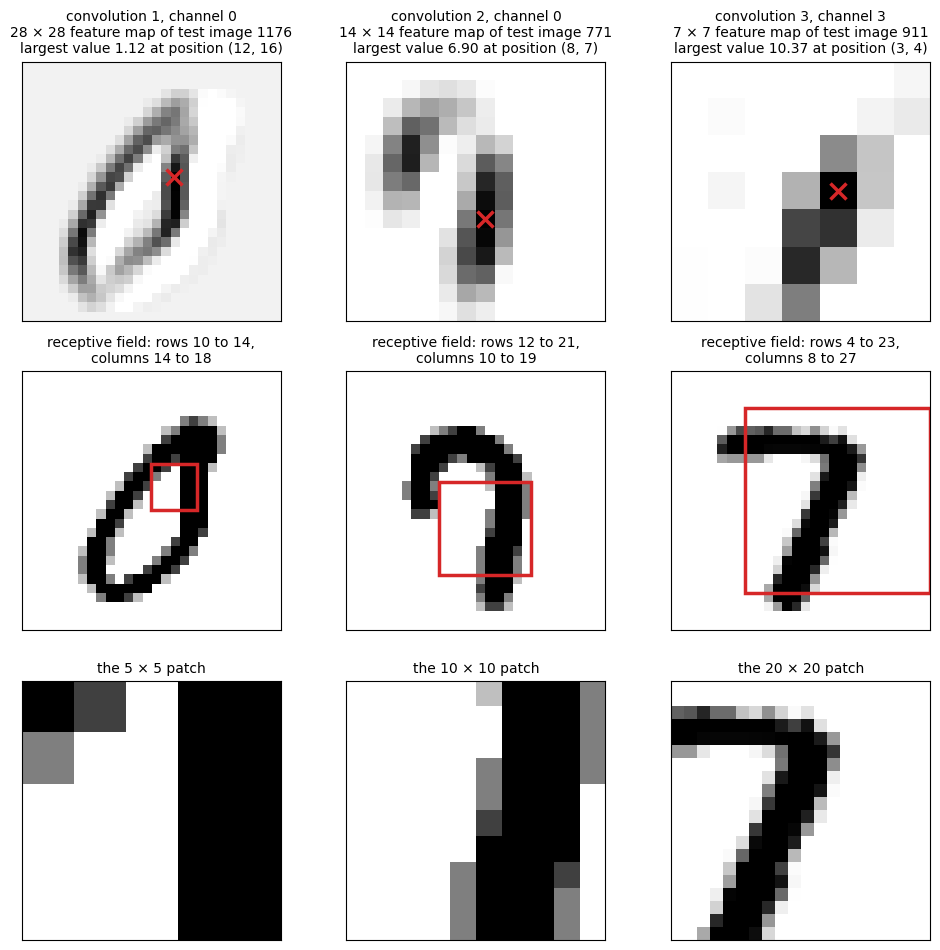

In [11]:
geometry = [(2, 1, 2, 5), (5, 2, 4, 10), (8, 4, 8, 20)]     # for each convolution: (n_layers, step, offset, size)
channels = [0, 0, 3]                                        # the channel to follow in each convolution
fig, axes = plt.subplots(3, 3, figsize=(10, 9.6))
for col, ((n_layers, step, offset, size), ch) in enumerate(zip(geometry, channels)):
    with torch.no_grad():
        acts = cnn[:n_layers](x_test)[:, ch]                # step 1: channel ch of the feature maps, (2000, h, w)
    h, w = acts.shape[1:]
    best, where = acts.reshape(len(x_test), -1).max(dim=1)  # step 2: the largest value in each image, and where
    img = best.argmax().item()                              # step 3: the image that ranks first
    i, j = divmod(where[img].item(), w)
    top, left = step * i - offset, step * j - offset        # step 4: the receptive field of position (i, j)

    axes[0, col].imshow(acts[img], cmap="gray_r")
    axes[0, col].plot(j, i, "x", color="C3", ms=12, mew=2.5)
    axes[0, col].set_title(f"convolution {col + 1}, channel {ch}\n{h} × {w} feature map of test image {img}\n"
                           f"largest value {best[img]:.2f} at position ({i}, {j})", fontsize=10)
    axes[1, col].imshow(x_test[img, 0], cmap="gray_r", vmin=0, vmax=1)
    axes[1, col].add_patch(plt.Rectangle((left - 0.5, top - 0.5), size, size, fill=False, edgecolor="C3", lw=2.5))
    axes[1, col].set(xlim=(-0.5, 27.5), ylim=(27.5, -0.5))
    axes[1, col].set_title(f"receptive field: rows {top} to {top + size - 1},\ncolumns {left} to {left + size - 1}",
                           fontsize=10)
    padded = F.pad(x_test[img, 0], (8, 8, 8, 8))            # zeros around the image, for fields beyond the border
    axes[2, col].imshow(padded[top + 8:top + 8 + size, left + 8:left + 8 + size], cmap="gray_r", vmin=0, vmax=1)
    axes[2, col].set_title(f"the {size} × {size} patch", fontsize=10)
for ax in axes.ravel():
    ax.set(xticks=[], yticks=[])
plt.tight_layout()
plt.show()

For the first 6 channels of each convolution, the next figure shows the
8 patches given by `top_patches`: one row per channel, from the largest
value (left) to the 8th largest (right).

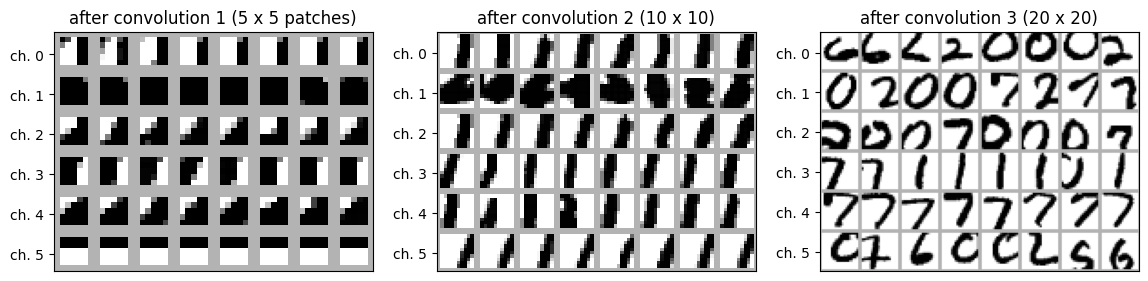

In [12]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (title, p) in zip(axes, patches.items()):
    p = F.pad(p[:6], (1, 1, 1, 1), value=0.3)                    # gray frame around each patch
    mosaic = torch.cat([torch.cat(list(row), dim=1) for row in p], dim=0)
    ax.imshow(mosaic, cmap="gray_r", vmin=0, vmax=1)
    size = p.shape[-1]
    ax.set(xticks=[], yticks=size * np.arange(6) + size / 2, yticklabels=[f"ch. {c}" for c in range(6)], title=title)
plt.show()

Within a row, the patches look alike: each channel has a preferred
pattern. The patterns get larger and more specific with depth:

- After the first convolution they are small pieces of strokes, and they
  match the kernels: the patches of channel 5 are black at the top and
  white below, those of channel 3 have the ink on the left, those of
  channel 0 on the right, and those of channel 1 (an ink detector) are
  entirely black.
- After the second, they are longer pieces: strokes close to vertical
  (channels 0, 2 and 4), slanted strokes (channels 3 and 5) and thick
  blobs of ink (channel 1).
- After the third, a patch covers most of a digit, and several channels
  prefer a few classes: channel 4 only shows 7s, channel 3 shows 1s and
  7s, channel 1 the round top of 0s, 2s and 7s.

This is the usual picture of a CNN: edges, then parts, then objects.

**A control.** The patches are crops of real digits, so they would look
like pieces of digits whatever the channels compute. What tells us
something about the network is that the patches look alike *within a
row*, and differ from row to row. To see how much of this we would get
by chance, the next figure has the same layout with random patches of
the same sizes: each one comes from a random test image, and is centered
on a random pixel with ink, so that it is not blank.

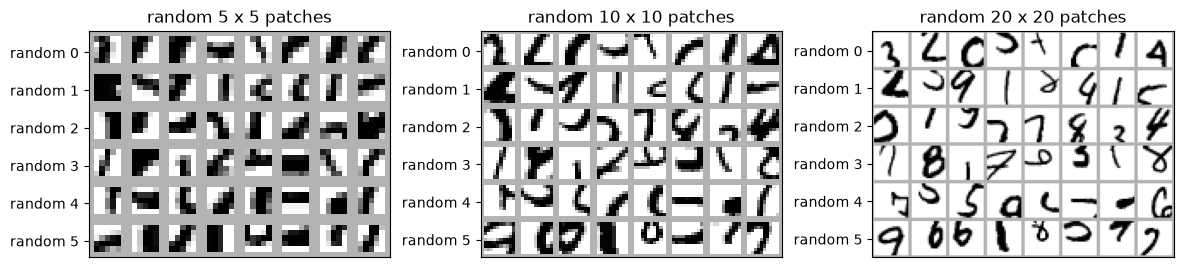

In [13]:
def random_patches(images, size, n_rows=6, n_top=8, seed=0):
    """n_rows x n_top patches of size x size, each from a different random image, centered on a random pixel
    with ink (value above 0.5), so that no patch is blank. Returns an array of shape (n_rows, n_top, size, size)."""
    gen = torch.Generator().manual_seed(seed)
    padded = F.pad(images, (size, size, size, size))            # so that patches at the border fit
    imgs = torch.randperm(len(images), generator=gen)[:n_rows * n_top]
    out = torch.zeros(n_rows * n_top, size, size)
    for t, img in enumerate(imgs):
        inked = (images[img, 0] > 0.5).nonzero()
        r, c = inked[torch.randint(len(inked), (1,), generator=gen).item()]
        top, left = r - size // 2 + size, c - size // 2 + size
        out[t] = padded[img, 0, top:top + size, left:left + size]
    return out.reshape(n_rows, n_top, size, size)


fig, axes = plt.subplots(1, 3, figsize=(14, 4), gridspec_kw={"wspace": 0.3})     # room for the row labels
for ax, size in zip(axes, (5, 10, 20)):
    p = F.pad(random_patches(x_test, size), (1, 1, 1, 1), value=0.3)      # gray frame around each patch
    mosaic = torch.cat([torch.cat(list(row), dim=1) for row in p], dim=0)
    ax.imshow(mosaic, cmap="gray_r", vmin=0, vmax=1)
    ax.set(xticks=[], yticks=(size + 2) * np.arange(6) + size / 2 + 1, yticklabels=[f"random {r}" for r in range(6)],
           title=f"random {size} x {size} patches")
plt.show()

Every random patch still looks like a piece of a digit, but the rows
have nothing in common: the strokes have all orientations and positions,
a few $5 \times 5$ patches are almost entirely black (inside a stroke,
with no edge), and the $20 \times 20$ patches show different digits at
different places. The rows of the previous figure are much more alike,
so their agreement comes from the channels, not from the data.

This is still a comparison by eye, and it only looks at the 8 largest
values of each channel. To test *what* a channel responds to, we have to
change the input and watch the value, as we did with the half-planes of
the tuning curves above.

# Initialization in a deep CNN

## What the lecture predicts

Before training, the weights are random. In lecture we saw what this
does to a deep ReLU network. Take a layer whose outputs each add up $N$
inputs, with independent weights of mean zero and variance $\sigma^2$.
If the preactivations of the previous layer have variance $s^2$, those
of this layer have variance about
$$\frac{N \sigma^2}{2} \, s^2 .$$
So every layer multiplies the variance by $N \sigma^2 / 2$. The same
factor (with the number of outputs in place of $N$) applies to the
gradients on the way back. After $L$ layers the variance has changed by
$(N \sigma^2 / 2)^L$, and the standard deviation by the square root of
that, which explodes or vanishes unless $N \sigma^2 / 2 = 1$. *He
initialization* takes $\sigma^2 = 2 / N$ (He et al. 2015; Prince 2023,
sec. 7.5).

For a convolution, $N = K^2 C_{\text{in}}$, as we saw above. We write
the variance of the weights as
$$\sigma^2 = \frac{c}{N},$$
so that the predicted factor per layer is $c / 2$, and He initialization
is $c = 2$.

## A deep CNN

The CNN of section 1 has only three convolutions, so a bad factor is
applied three times. To see the effect we use a deeper network: 20
convolutions ($3 \times 3$, 16 channels, each followed by a ReLU) with
no pooling between them, then the average of each channel over the image
and one fully connected layer. To make it fast, the images are first
reduced to $14 \times 14$ by averaging $2 \times 2$ blocks.

In [14]:
def make_deep_cnn(c=None, depth=20, width=16):
    """A plain deep CNN on 14 x 14 images. With c=None the weights keep PyTorch's default initialization.
    Otherwise the weights of each convolution are normal with variance c / N, N = 9 * (input channels),
    and its biases are zero."""
    layers, c_in = [nn.AvgPool2d(2)], 1                          # 1 x 28 x 28 -> 1 x 14 x 14
    for _ in range(depth):
        conv = nn.Conv2d(c_in, width, kernel_size=3, padding=1)
        if c is not None:
            nn.init.normal_(conv.weight, std=np.sqrt(c / (9 * c_in)))
            nn.init.zeros_(conv.bias)
        layers += [conv, nn.ReLU()]
        c_in = width
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(width, 10)]    # average each channel, then 10 logits
    return nn.Sequential(*layers)


n_params = sum(p.numel() for p in make_deep_cnn().parameters())
print(f"{n_params:,} parameters")

44,410 parameters

## The scale of each layer before training

We pass 256 training images through the network *before any training*,
compute the loss and its gradient, and record three numbers for each
convolution:

- the standard deviation of its preactivations (its outputs, before the
  ReLU);
- the standard deviation of its preactivations *across images*, at a
  fixed channel and position, averaged over channels and positions: how
  much the layer still depends on the input;
- the standard deviation of the derivative of the loss with respect to
  its preactivations.

We do this for $c = 0.5$, $2$ (He) and $8$, and for PyTorch’s default.

In [15]:
def layer_scales(model, xb, yb):
    """Pass a minibatch through the model and backpropagate the loss. For each convolution, return the standard
    deviation of (1) its preactivations, (2) its preactivations across images, (3) the gradient of the loss with
    respect to its preactivations."""
    preacts, h = [], xb
    for layer in model:
        h = layer(h)
        if isinstance(layer, nn.Conv2d):
            h.retain_grad()                      # keep d loss / d h after backward()
            preacts.append(h)
    F.cross_entropy(h, yb).backward()
    return (np.array([p.std().item() for p in preacts]),
            np.array([p.std(dim=0).mean().item() for p in preacts]),
            np.array([p.grad.std().item() for p in preacts]))


xb, yb = next(iter(torch.utils.data.DataLoader(train_set, batch_size=256)))
inits = {"c = 0.5": 0.5, "c = 2 (He)": 2, "c = 8": 8, "PyTorch default": None}
scales = {}
for name, c in inits.items():
    torch.manual_seed(0)
    scales[name] = layer_scales(make_deep_cnn(c), xb, yb)

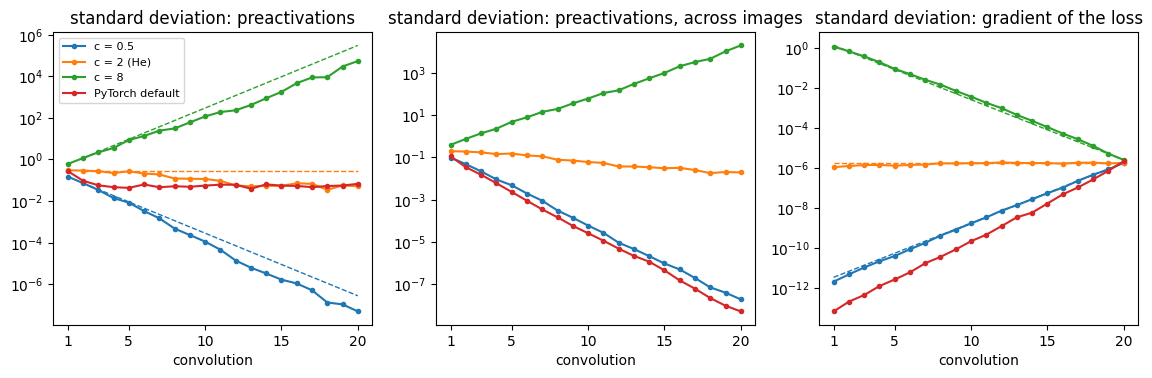

variance factor per layer         forward    backward    predicted
c = 0.5                              0.20       0.24    0.25
c = 2 (He)                           0.80       0.96    1.00
c = 8                                3.19       3.94    4.00
PyTorch default                      0.99       0.17    see below

In [16]:
layers = np.arange(1, 21)
titles = ["preactivations", "preactivations, across images", "gradient of the loss"]
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for i, (name, c) in enumerate(inits.items()):
    for ax, s in zip(axes, scales[name]):
        ax.plot(layers, s, "o-", ms=3, color=f"C{i}", label=name)
    if c is not None:        # the lecture's prediction: the variance changes by c / 2 per layer
        fwd, _, bwd = scales[name]
        axes[0].plot(layers[1:], fwd[1] * (c / 2) ** ((layers[1:] - 2) / 2), "--", color=f"C{i}", lw=1)
        axes[2].plot(layers, bwd[-1] * (c / 2) ** ((20 - layers) / 2), "--", color=f"C{i}", lw=1)
for ax, title in zip(axes, titles):
    ax.set(yscale="log", xlabel="convolution", title=f"standard deviation: {title}", xticks=[1, 5, 10, 15, 20])
axes[0].legend(fontsize=8)
plt.show()

print("variance factor per layer         forward    backward    predicted")
for name, c in inits.items():
    fwd, _, bwd = scales[name]
    f_fwd = np.exp(np.polyfit(layers[1:], np.log(fwd[1:] ** 2), 1)[0])       # from convolution 2 on
    f_bwd = np.exp(-np.polyfit(layers, np.log(bwd ** 2), 1)[0])
    pred = f"{c / 2:.2f}" if c is not None else "see below"
    print(f"{name:<32} {f_fwd:8.2f}  {f_bwd:9.2f}    {pred}")

The dashed lines are the lecture’s prediction, starting from the second
convolution (left) and from the last one (right). The table gives the
measured factor by which the variance changes per layer.

- **Backward pass.** The measured factors (0.24, 0.96 and 3.94) are
  close to the predicted $c / 2$ (0.25, 1 and 4). With $c = 0.5$ the
  gradient at the first convolution is about a million times smaller
  than at the last one, and with $c = 8$ about half a million times
  larger.
- **Forward pass.** The measured factors (0.20, 0.80 and 3.19) are all
  about 20% below the prediction, so even with He initialization the
  preactivations shrink slowly, from about 0.3 to 0.05 over 20 layers.
  The prediction still gives the right picture: with $c = 0.5$ the
  preactivations of the last convolution are about $10^{-7}$, and with
  $c = 8$ about $10^{5}$.
- **PyTorch’s default** looks fine in the left panel, but not in the
  other two: across images, its preactivations shrink even faster than
  with $c = 0.5$, and so do its gradients. After 20 layers the network
  computes almost the same numbers for every image. The next section
  explains why.

Why are the three forward factors all 20% low? With the same seed, the
three networks have the same weights up to a constant factor, and
multiplying the weights of a ReLU network without biases by a constant
only rescales the preactivations of each layer. So this is a single
measurement, seen three times. The lecture’s factor is an average over
the random weights, and with only 16 channels one draw of the weights
can be far from it: with seeds 0 to 9, the forward factor for He
initialization ranges from 0.76 to 1.19 (and the backward factor from
0.91 to 1.21). Zero padding at the borders lowers it by about 2% more.

## PyTorch’s default

What does PyTorch do if we do not initialize the weights ourselves? We
can measure the variance of the default weights and multiply it by $N$:

In [17]:
torch.manual_seed(0)
conv = nn.Conv2d(64, 64, kernel_size=3)          # N = 9 * 64 = 576
linear = nn.Linear(500, 500)                     # N = 500
print(f"nn.Conv2d: N x variance of the weights = {576 * conv.weight.var().item():.3f}")
print(f"nn.Linear: N x variance of the weights = {500 * linear.weight.var().item():.3f}")
print(f"nn.Conv2d: largest bias {conv.bias.abs().max().item():.4f},  1 / sqrt(N) = {1 / np.sqrt(576):.4f}")

nn.Conv2d: N x variance of the weights = 0.332
nn.Linear: N x variance of the weights = 0.334
nn.Conv2d: largest bias 0.0417,  1 / sqrt(N) = 0.0417

The default weights have variance $1 / (3N)$: this is $c = 1/3$, six
times smaller than He initialization. The predicted factor per layer is
$c / 2 = 1/6 \approx 0.17$, which is the backward factor we measured.

The default also draws the biases at random, uniformly between
$-1 / \sqrt{N}$ and $1 / \sqrt{N}$, instead of setting them to zero.
Each layer adds its biases to a signal that has almost vanished, so the
preactivations keep a standard deviation of about 0.05 (left panel
above), the size of the biases ($1 / \sqrt{3N} \approx 0.05$ for
$N = 144$), but they come from the biases and are the same for every
image (middle panel).

This did not matter in lab 10. With three convolutions, a factor of this
size is applied only three times, so the scale of the gradients changes
by a factor of the order of 10 (for example $\sqrt{6^3} \approx 15$),
not millions, and Adam adapts its steps to the scale of the gradients.
(The exact factors differ there, because the number of channels doubles
at each convolution and max pooling changes the scale.) It matters for
deep networks.

## Does it matter for training?

We now train the four networks in the same way: Adam with learning rate
$10^{-3}$, for 6 epochs on the first 5,000 training images (a small
budget, to keep this fast).

In [18]:
small_loader = torch.utils.data.DataLoader(torch.utils.data.Subset(train_set, range(5000)),
                                           batch_size=128, shuffle=True)
deep_histories = {}
for name, c in inits.items():
    torch.manual_seed(0)
    deep_histories[name] = train(make_deep_cnn(c), small_loader, n_epochs=6, verbose=False)
    h = deep_histories[name]
    print(f"{name:<16} training loss: " + "  ".join(f"{v:8.2f}" for v in h["train_loss"])
          + f"   validation accuracy {h['val_acc'][-1]:.1%}")

c = 0.5          training loss:     2.30      2.30      2.27      2.14      2.30      2.30   validation accuracy 10.8%
c = 2 (He)       training loss:     2.17      1.76      1.65      1.00      0.76      0.56   validation accuracy 87.7%
c = 8            training loss:  1855.75     32.47     13.00     11.16     10.03      9.28   validation accuracy 10.7%
PyTorch default  training loss:     2.32      2.28      2.18      2.05      1.96      1.66   validation accuracy 45.8%

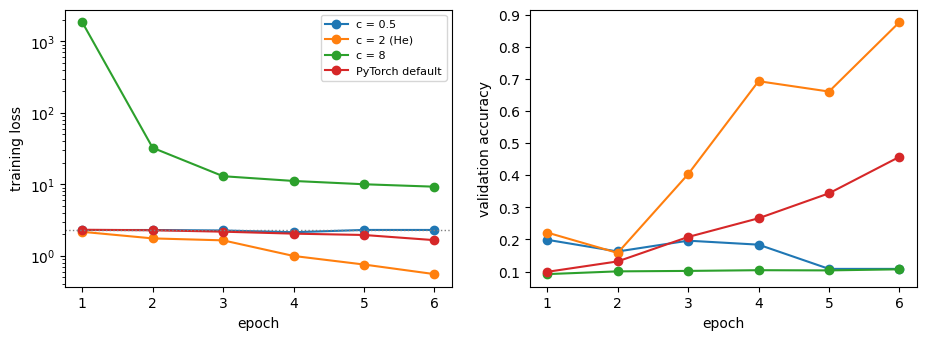

In [19]:
epochs = range(1, 7)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name, h in deep_histories.items():
    axes[0].plot(epochs, h["train_loss"], "o-", label=name)
    axes[1].plot(epochs, h["val_acc"], "o-", label=name)
axes[0].axhline(np.log(10), color="gray", ls=":", lw=1)
axes[0].set(xlabel="epoch", ylabel="training loss", yscale="log")
axes[1].set(xlabel="epoch", ylabel="validation accuracy")
axes[0].legend(fontsize=8)
plt.show()

The dotted line is $\log 10 \approx 2.30$, the loss of a network that
gives probability $1/10$ to every class.

- **He initialization** trains: after a slow first epoch (2.17, just
  below the dotted line), the training loss falls to 0.56 and the
  validation accuracy reaches 87.7%.
- **PyTorch’s default** does learn, but slowly: 45.8% after the same 6
  epochs. Adam has to grow the weights before the output depends on the
  image.
- **$c = 0.5$** ends at the dotted line (10.8%). The loss goes down a
  little in epoch 4 (2.14) and comes back to 2.30: the network predicts
  the same probabilities for every image.
- **$c = 8$** starts with a loss of about 1,856, because its logits are
  huge, and is still at 9.28 after 6 epochs, with 10.7% accuracy.

These are single runs with one seed, and a too-small scale is not always
fatal with Adam. But the ranking is what the computation suggests: the
further $N \sigma^2 / 2$ is from 1, the harder the first steps of
training.

Initialization alone is not what makes very deep networks trainable in
practice. Residual connections and normalization layers keep the scales
under control during training as well (Prince 2023, ch. 11).

# Robustness to perturbations

Lab 10 ended with robustness to shifts. Here we look at another
perturbation, the one we used for training in section 1: independent
normal noise added to every pixel (pixel values are between 0 and 1),
computed by `add_noise`. We start from `cnn_default`, the first network
of section 1, which was trained on clean images only.

In [20]:
def noise_accuracy(model, sd):
    """Test accuracy on images with noise of standard deviation sd."""
    torch.manual_seed(1)                         # the same noise for every model
    return evaluate(model, test_loader, transform=lambda images: add_noise(images, sd))[1]


noise_sds = [0, 0.1, 0.2, 0.3, 0.5, 0.75, 1.0]

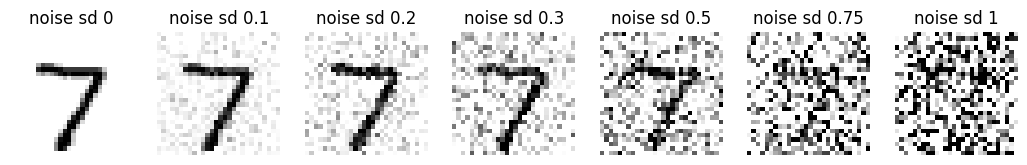

cnn_default:  sd 0: 98.0%,  sd 0.1: 97.7%,  sd 0.2: 96.8%,  sd 0.3: 93.3%,  sd 0.5: 68.1%,  sd 0.75: 38.5%,  sd 1: 25.0%

In [21]:
torch.manual_seed(0)
fig, axes = plt.subplots(1, len(noise_sds), figsize=(13, 2.1))
for ax, sd in zip(axes, noise_sds):
    ax.imshow(add_noise(x_test[0], sd)[0], cmap="gray_r", vmin=0, vmax=1)
    ax.set_title(f"noise sd {sd:g}")
    ax.axis("off")
plt.show()

noise_accs = {"no augmentation": [noise_accuracy(cnn_default, sd) for sd in noise_sds]}
print("cnn_default:  " + ",  ".join(f"sd {sd:g}: {a:.1%}" for sd, a in zip(noise_sds, noise_accs["no augmentation"])))

This CNN has never seen a noisy image. Its accuracy holds up to a
standard deviation of about 0.2 (96.8%), then falls quickly: 93.3% at
0.3, 68.1% at 0.5 and 25.0% at 1. At 0.5 the digit is still easy to read
for us.

## Noise augmentation

As for shifts in lab 10, we can train on perturbed images. We train
three more copies of `cnn_default` (default initialization, same seed
and budget): one with the noise augmentation of section 1
(`random_noise`), one on images shifted at random by up to 3 pixels in
each direction, as in lab 10 (`random_shift`), and one with both: each
minibatch is shifted, then noise is added.

In [22]:
def random_shift(images):
    dx, dy = torch.randint(-3, 4, (2,)).tolist()
    return shift(images, dx, dy)


def random_shift_and_noise(images):
    return random_noise(random_shift(images))


cnns = {"no augmentation": cnn_default}
for name, transform in [("noise augmentation", random_noise), ("shift augmentation", random_shift),
                        ("noise + shift augmentation", random_shift_and_noise)]:
    torch.manual_seed(0)
    cnns[name] = make_cnn5()
    train(cnns[name], train_loader, n_epochs=3, transform=transform, verbose=False)
    noise_accs[name] = [noise_accuracy(cnns[name], sd) for sd in noise_sds]

shifts = [0, 1, 2, 3, 4]
shift_accs = {name: [shift_accuracy(model, k) for k in shifts] for name, model in cnns.items()}

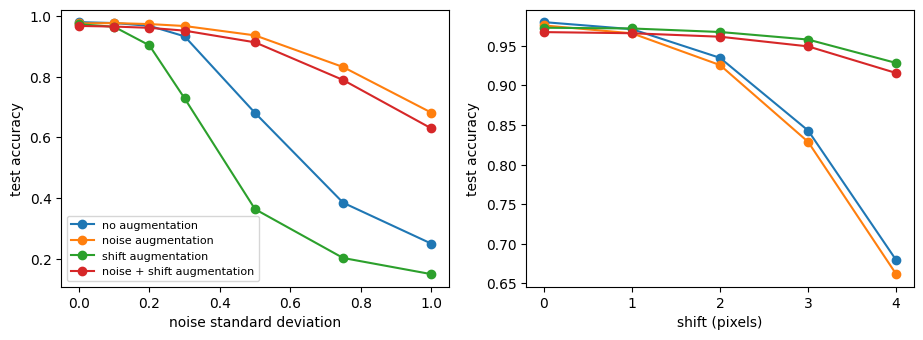

test accuracy                  clean  noise sd 0.5  noise sd 1  shift 3 px
no augmentation                98.0%         68.1%       25.0%       84.3%
noise augmentation             97.6%         93.6%       68.2%       82.9%
shift augmentation             97.3%         36.4%       14.9%       95.8%
noise + shift augmentation     96.7%         91.3%       63.0%       94.9%

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for name in cnns:
    axes[0].plot(noise_sds, noise_accs[name], "o-", label=name)
    axes[1].plot(shifts, shift_accs[name], "o-", label=name)
axes[0].set(xlabel="noise standard deviation", ylabel="test accuracy")
axes[1].set(xlabel="shift (pixels)", ylabel="test accuracy", xticks=shifts)
axes[0].legend(fontsize=8)
plt.show()

print(f"{'test accuracy':<28} {'clean':>7} {'noise sd 0.5':>13} {'noise sd 1':>11} {'shift 3 px':>11}")
for name in cnns:
    print(f"{name:<28} {noise_accs[name][0]:>7.1%} {noise_accs[name][4]:>13.1%} {noise_accs[name][6]:>11.1%} "
          f"{shift_accs[name][3]:>11.1%}")

- **Noise augmentation works.** At a noise standard deviation of 0.5,
  the accuracy goes from 68.1% to 93.6%, and at 1, twice the largest
  noise seen in training, from 25.0% to 68.2%. The cost on clean images
  is small (98.0% to 97.6%).
- **Robustness is specific to the perturbation.** Shift augmentation
  gives 95.8% on images shifted by 3 pixels, against 84.3% without it,
  but it does not help against noise. It makes it worse: 36.4% at
  standard deviation 0.5, against 68.1% with no augmentation. In the
  other direction, noise augmentation does not help against shifts
  (82.9%).
- **Mixing the two gets most of both.** The network trained on images
  both shifted and noisy reaches 94.9% under a shift of 3 pixels (95.8%
  with shifts alone) and 91.3% under noise of standard deviation 0.5
  (93.6% with noise alone). It gives up a little on each perturbation,
  more at the largest noise (63.0% against 68.2% at standard deviation
  1), and a little on clean images (96.7%, the lowest of the four): with
  the same budget it has more to learn.

Augmentation teaches the network the perturbations it is shown, and
nothing says that it will be robust to the others. If we do not know
which perturbations the test images will have, we have to guess them,
and showing several at once is cheap here: one network handles both, at
a small cost on each.

## Digits from another source

The perturbations so far were ones we chose. To see whether robustness
helps on images that differ from the training images in ways we did not
choose, we test the networks on the USPS digits: 9,298 handwritten
digits scanned from envelopes by the US Postal Service (Hull 1994). They
are $16 \times 16$ images, in
[usps_X.npy](../../datasets/nn_lab_cont/usps/usps_X.npy) (shape
`(9298, 16, 16)`, integer values between 0 and 255) and
[usps_y.npy](../../datasets/nn_lab_cont/usps/usps_y.npy) (the labels,
from 0 to 9). We resize them to $28 \times 28$, the size the networks
expect.

In [24]:
X_usps = np.load("../../datasets/nn_lab_cont/usps/usps_X.npy")                # uint8, shape (9298, 16, 16), ink is high
y_usps = torch.tensor(np.load("../../datasets/nn_lab_cont/usps/usps_y.npy"))
x_usps = F.interpolate(torch.tensor(X_usps).float().div(255).unsqueeze(1), size=28, mode="bilinear")   # (9298, 1, 28, 28)
usps_loader = torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x_usps, y_usps), batch_size=1000)

usps_accs = {name: evaluate(model, usps_loader)[1] for name, model in cnns.items()}
print(f"{'test accuracy':<28} {'MNIST':>7} {'USPS':>7}")
for name in cnns:
    print(f"{name:<28} {noise_accs[name][0]:>7.1%} {usps_accs[name]:>7.1%}")

test accuracy                  MNIST    USPS
no augmentation                98.0%   82.8%
noise augmentation             97.5%   76.9%
shift augmentation             97.3%   78.2%
noise + shift augmentation     96.5%   85.7%

All four networks lose between 11 and 21 points on USPS. The
augmentations of the previous section do not help: noise and shift alone
do worse than no augmentation (76.9% and 78.2% against 82.8%). Their
combination does better here (85.7%), but not with seeds 1 and 2 (62.2%
and 74.4%, against 73.0% and 82.2% with no augmentation; not shown).

To find what makes USPS different, we look at the data: a few images of
each data set, and the height of the digits, the number of rows from the
first to the last row with ink.

In [25]:
def digit_height(images):
    """Number of rows from the first to the last row with ink (a pixel above 0.5), for each image."""
    ink_rows = (images[:, 0] > 0.5).any(dim=2).float()          # (n, 28): 1 if the row has ink
    first = ink_rows.argmax(dim=1)
    last = 27 - ink_rows.flip(1).argmax(dim=1)
    return (last - first + 1).numpy()


heights = {"MNIST": digit_height(x_test), "USPS": digit_height(x_usps)}
print("median height (pixels): " + ",  ".join(f"{name} {np.median(h):.0f}" for name, h in heights.items()))

median height (pixels): MNIST 20,  USPS 27

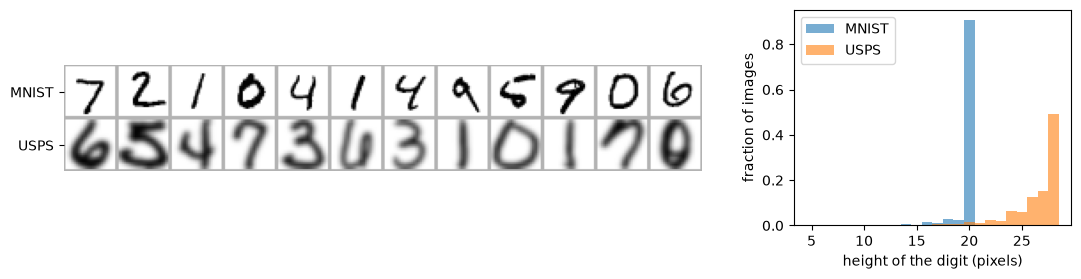

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8), gridspec_kw={"width_ratios": [2.3, 1]})
framed = [F.pad(x[:12, 0], (1, 1, 1, 1), value=0.3) for x in (x_test, x_usps)]   # gray frame around each image
axes[0].imshow(torch.cat([torch.cat(list(f), dim=1) for f in framed], dim=0), cmap="gray_r", vmin=0, vmax=1)
axes[0].set(xticks=[], yticks=[15, 45], yticklabels=["MNIST", "USPS"])
for side in axes[0].spines.values():
    side.set_visible(False)
for name, h in heights.items():
    axes[1].hist(h, bins=np.arange(4.5, 29), alpha=0.6, density=True, label=name)
axes[1].set(xlabel="height of the digit (pixels)", ylabel="fraction of images")
axes[1].legend()
plt.show()

MNIST digits are 20 pixels tall: they were scaled to fit in a
$20 \times 20$ box and centered in the $28 \times 28$ image (LeCun et
al. 1998). USPS digits fill the image: 27 pixels, about 1.4 times
larger. Our augmentations change the noise and the position, never the
size, so it is no surprise that they do not help. The perturbation to be
robust to is a change of *scale*. We train one more copy of
`cnn_default`, on training images zoomed by a random factor between 0.7
and 1.5, a range that includes 1.4. `random_scale` draws a factor for
each image and resamples the image with `F.affine_grid` and
`F.grid_sample`.

In [27]:
def random_scale(images, low=0.7, high=1.5):
    """Zoom each image about its center by its own random factor between low and high (zeros outside the image)."""
    s = torch.empty(len(images)).uniform_(low, high)
    theta = torch.zeros(len(images), 2, 3)
    theta[:, 0, 0] = theta[:, 1, 1] = 1 / s           # the output at position p (from the center) is the input at p / s
    grid = F.affine_grid(theta, images.shape, align_corners=False)
    return F.grid_sample(images, grid, align_corners=False)


torch.manual_seed(0)
cnn_scale = make_cnn5()
train(cnn_scale, train_loader, n_epochs=3, transform=random_scale, verbose=False)
print(f"{'scale augmentation':<28} {evaluate(cnn_scale, test_loader)[1]:>7.1%} {evaluate(cnn_scale, usps_loader)[1]:>7.1%}")

scale augmentation             96.3%   88.5%

Scale augmentation brings USPS from 82.8% to 88.5%, at a cost of 1.7
points on MNIST in this run. With seeds 1 and 2 (not shown) the gain is
larger, from 73.0% to 92.5% and from 82.2% to 89.9%, and the cost on
MNIST at most 0.4 points.

So robustness does help on data from another source, if it is robustness
to the right perturbation, and looking at the data told us which one.
The same observation also gives a fix without retraining: shrink the
USPS digits to fit in a $20 \times 20$ box, as was done for MNIST. With
this preprocessing `cnn_default` gets about 96% of them right (not
shown).

# References

**Edge detectors, channels and receptive fields.** Orientation tuning
and receptive fields come from neuroscience: Hubel and Wiesel (1962)
recorded single neurons in the visual cortex of cats and found cells
that respond to an edge or a bar at one orientation, in one region of
the visual field. The first layer of a CNN trained on natural images
learns kernels of the same kind, edge detectors at many orientations and
color blobs (Krizhevsky et al. 2012, fig. 3). Looking at the input
patches that make a channel the largest, as we did for the three
convolutions, is the approach of Zeiler and Fergus (2014), who found the
same progression from edges to parts to objects in a large network. Olah
et al. (2017) survey this and other ways to see what a channel detects,
including synthesizing the input that a channel responds to the most.
For CNNs in general, see Prince (2023, chap. 10) and LeCun et al.
(1998).

**Initialization.** Glorot and Bengio (2010) studied how the scale of
the activations and of the gradients changes across the layers of a deep
network, and proposed to choose the variance of the weights to keep it
constant. He et al. (2015) adapted the argument to ReLU networks, which
gives the factor $c / 2$ per layer of section 2. See also Prince (2023,
sec. 7.5).

**Robustness and augmentation.** Geirhos et al. (2018) trained networks
on images with one kind of distortion, such as additive noise, and found
that they became robust to that distortion and generally not to the
others, as in our comparison of noise and shift augmentation. Hendrycks
and Dietterich (2019) built a benchmark of common corruptions (noise,
blur, weather, digital artifacts) to measure this kind of robustness.
Azulay and Weiss (2019) show that even large CNNs can change their
prediction when the image is shifted by one pixel, although the
convolutions alone are equivariant to shifts. Shorten and Khoshgoftaar
(2019) survey the data augmentation methods used for images.

Azulay, Aharon, and Yair Weiss. 2019. “Why Do Deep Convolutional
Networks Generalize so Poorly to Small Image Transformations?” *Journal
of Machine Learning Research* 20 (184): 1–25.

Geirhos, Robert, Carlos R. Medina Temme, Jonas Rauber, Heiko H. Schütt,
Matthias Bethge, and Felix A. Wichmann. 2018. “Generalisation in Humans
and Deep Neural Networks.” *Advances in Neural Information Processing
Systems* 31.

Glorot, Xavier, and Yoshua Bengio. 2010. “Understanding the Difficulty
of Training Deep Feedforward Neural Networks.” *Proceedings of the
Thirteenth International Conference on Artificial Intelligence and
Statistics (AISTATS)*, 249–56.

He, Kaiming, Xiangyu Zhang, Shaoqing Ren, and Jian Sun. 2015. “Delving
Deep into Rectifiers: Surpassing Human-Level Performance on ImageNet
Classification.” *Proceedings of the IEEE International Conference on
Computer Vision*, 1026–34.

Hendrycks, Dan, and Thomas Dietterich. 2019. “Benchmarking Neural
Network Robustness to Common Corruptions and Perturbations.”
*International Conference on Learning Representations*.

Hubel, David H., and Torsten N. Wiesel. 1962. “Receptive Fields,
Binocular Interaction and Functional Architecture in the Cat’s Visual
Cortex.” *The Journal of Physiology* 160 (1): 106–54.

Hull, Jonathan J. 1994. “A Database for Handwritten Text Recognition
Research.” *IEEE Transactions on Pattern Analysis and Machine
Intelligence* 16 (5): 550–54.

Krizhevsky, Alex, Ilya Sutskever, and Geoffrey E. Hinton. 2012.
“ImageNet Classification with Deep Convolutional Neural Networks.”
*Advances in Neural Information Processing Systems* 25.

LeCun, Yann, Léon Bottou, Yoshua Bengio, and Patrick Haffner. 1998.
“Gradient-Based Learning Applied to Document Recognition.” *Proceedings
of the IEEE* 86 (11): 2278–324.

Olah, Chris, Alexander Mordvintsev, and Ludwig Schubert. 2017. “Feature
Visualization.” *Distill* 2 (11).
<https://doi.org/10.23915/distill.00007>.

Prince, Simon J. D. 2023. *Understanding Deep Learning*. The MIT Press.
<http://udlbook.com>.

Shorten, Connor, and Taghi M. Khoshgoftaar. 2019. “A Survey on Image
Data Augmentation for Deep Learning.” *Journal of Big Data* 6: 60.

Zeiler, Matthew D., and Rob Fergus. 2014. “Visualizing and Understanding
Convolutional Networks.” *European Conference on Computer Vision
(ECCV)*, 818–33.